## Challenge 2: Make the Quantum Coin Biased

### Predictions
- Circuit A: Approximately 75% `0` and 25% `1`.
- Circuit B: Approximately 25% `0` and 75% `1`.

### Explanation
The RY gate rotates the qubit's quantum state by a chosen angle. Different rotation angles produce different measurement probabilities.

In Circuit A, the selected angle makes the probability of measuring `0` greater than the probability of measuring `1`. In Circuit B, the angle makes `1` more likely than `0`.

The measured counts may differ slightly from the predicted percentages because each circuit is executed for only 100 shots.

### Challenge Question
**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

Quantum gates change the qubit's quantum state. Depending on the gate and its parameters, the probability of measuring `0` or `1` can change. For example, the RY gate rotates the qubit's state, allowing us to create different measurement probability distributions.
### Actual Results

- **Circuit A — Favor 0:** 76 measurements of `0` and 24 measurements of `1`.
- **Circuit B — Favor 1:** 22 measurements of `0` and 78 measurements of `1`.

### Conclusion

Both circuits successfully produced biased measurement distributions. Circuit A favored `0`, while Circuit B favored `1`. The observed results were close to the predicted probabilities of 75%/25% and 25%/75%, respectively. This demonstrates that changing the RY rotation angle changes the measurement probabilities of a qubit.


Circuit A - Favor 0
     ┌─────────┐┌─┐
  q: ┤ Ry(π/3) ├┤M├
     └─────────┘└╥┘
c: 1/════════════╩═
                 0 
Measurement results: {'1': 22, '0': 78}
Total shots: 100


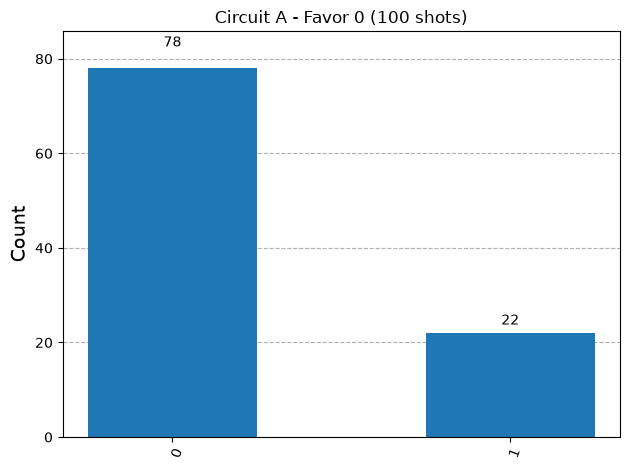


Circuit B - Favor 1
     ┌──────────┐┌─┐
  q: ┤ Ry(2π/3) ├┤M├
     └──────────┘└╥┘
c: 1/═════════════╩═
                  0 
Measurement results: {'1': 71, '0': 29}
Total shots: 100


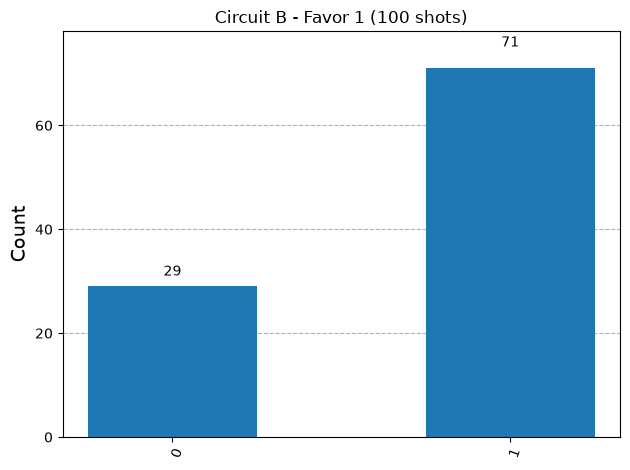

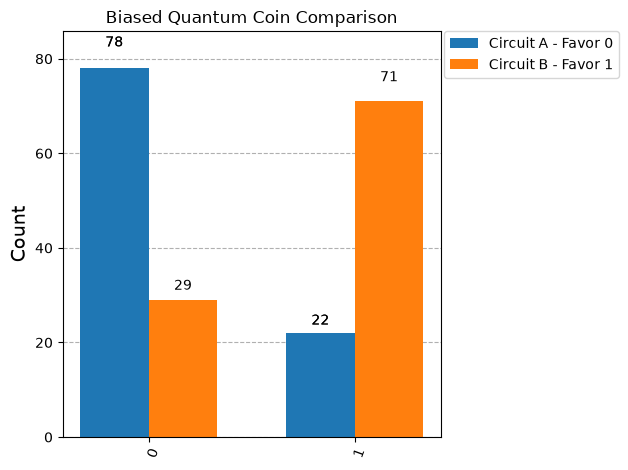

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import numpy as np

simulator = AerSimulator()

# Circuit A: Make 0 more likely
circuit_a = QuantumCircuit(1, 1)
circuit_a.ry(np.pi / 3, 0)
circuit_a.measure(0, 0)

# Circuit B: Make 1 more likely
circuit_b = QuantumCircuit(1, 1)
circuit_b.ry(2 * np.pi / 3, 0)
circuit_b.measure(0, 0)

circuits = {
    "Circuit A - Favor 0": circuit_a,
    "Circuit B - Favor 1": circuit_b
}

results = {}

for name, circuit in circuits.items():
    result = simulator.run(circuit, shots=100).result()
    counts = result.get_counts()
    results[name] = counts

    print(f"\n{name}")
    print(circuit.draw(output="text"))
    print("Measurement results:", counts)
    print("Total shots:", sum(counts.values()))

    display(plot_histogram(counts, title=f"{name} (100 shots)"))

# Compare both circuits in one histogram
display(
    plot_histogram(
        [dict(counts) for counts in results.values()],
        legend=list(results.keys()),
        title="Biased Quantum Coin Comparison"
    )
)